In [1]:
import os
os.chdir('/workspace/f3e551e9-af46-4df1-b06c-4e239c09209b')
print(os.listdir('.'))


['rho0.npy', 'memory', 'a.npy', 'a_n.npy', '.kernel_llm_logs_1.txt', '.prompts', 'N.npy', 'lambda_n.npy', ' v6 — Binding Context Document.pdf', 'c.npy', 'description.npy', '.config']


In [2]:
import numpy as np
# Inspect the loose .npy files to understand which function they belong to
for f in ['N.npy', 'c.npy', 'rho0.npy', 'description.npy']:
 arr = np.load(f, allow_pickle=True)
 print(f, arr.shape, arr.dtype, repr(arr)[:200])


N.npy () int64 array(1000000)
c.npy () complex128 array(-0.1656733+1.90092523j)
rho0.npy () complex128 array(0.7+7.j)
description.npy () <U334 array('F12 coefficients a_n = chi3(n) + c*chi5(n), n=1..1e6, where chi3, chi5 are the real primitive Dirichlet characters mod 3 and 5, and c = -0.16567330026345564 + 1.9009252335917202i is chosen so L


In [3]:
a = np.load('a.npy')
a_n = np.load('a_n.npy', allow_pickle=True)
lam = np.load('lambda_n.npy', allow_pickle=True)
print('a:', a.shape, a.dtype, a[:5])
print('a_n:', a_n.shape, a_n.dtype, a_n[:5])
print('lambda_n:', lam.shape, lam.dtype, lam[:5])


a: (1000000,) complex128 [ 0.8343267+1.90092523j -0.8343267-1.90092523j 0.1656733-1.90092523j
 0.8343267+1.90092523j -1. +0.j ]
a_n: (1000000,) object [1 -1472 -113643 5181440 -25499225]
lambda_n: (1000000,) float64 [ 1. -0.71875 -0.64151806 1.23535156 -0.52222413]


In [4]:
# So we have F12 fully (a.npy = a, c.npy, rho0.npy)
# And a_n.npy + lambda_n.npy looks like ONE of F9/F10/F11. Let's identify.
# F9 (Ramanujan Delta tau): tau(1)=1, tau(2)=-24, tau(3)=252, tau(4)=-1472, tau(5)=4830
# F10 (level-11 weight 2 11.2.a.a): a_1=1, a_2=-2, a_3=-1, a_4=2, a_5=1, a_6=2, a_7=-2, a_8=0, a_9=-2, a_10=-2
# F11 Sym^2 Delta: b_1=1, ...
# Our a_n[:5] = [1, -1472, -113643, 5181440, -25499225]
# That doesn't look like F9 or F10. Let's check F11:
# b_p = tau(p)^2 - p^11
# tau(2)=-24, tau(2)^2 = 576, 2^11 = 2048, b_2 = 576 - 2048 = -1472. YES!
# tau(3)=252, tau(3)^2 = 63504, 3^11 = 177147, b_3 = 63504 - 177147 = -113643. YES!
# So a_n is F11 (Sym^2 Delta)
print('Confirmed: a_n.npy / lambda_n.npy is F11 (Sym^2 Delta)')
print('lambda for F11 should be b_n / n^11; check b_2/2^11 =', -1472/2048)


Confirmed: a_n.npy / lambda_n.npy is F11 (Sym^2 Delta)
lambda for F11 should be b_n / n^11; check b_2/2^11 = -0.71875


In [5]:
# Plan:
# 1. Generate coefficients for each function class for n=1..N (N=1e6)
# F1: a_n = 1
# F2: chi mod 5 (real character, "chi_4" -- the unique real non-principal char mod 5: chi(1)=1, chi(2)=-1, chi(3)=-1, chi(4)=1, chi(0)=0)
# Actually note: there are characters mod 5 of order 4 (complex). "chi_4 mod 5" likely means the character of order 4. 
# But for L-function of a Dirichlet character, both work. Let's use the real primitive character mod 5.
# Actually mod 5 has 4 characters: trivial, two complex of order 4, and one real of order 2 (Legendre symbol).
# "chi_4" probably means the order-4 character. Let's use that (complex).
# F4: L_DH(s) — Davenport-Heilbronn function. Standard form:
# f(s) = (1-i tan(theta)) L(s, chi5_a) + (1+i tan(theta)) L(s, chi5_b)
# where chi5_a, chi5_b are the two complex characters mod 5, theta chosen so coefficients are real.
# Standard formula from Titchmarsh: f(n) = a_n where a_1=1, a_2=xi, a_3=-xi, a_4=-1, a_5=0, a_n+5 = a_n,
# with xi = (sqrt(10-2sqrt(5)) - 2) / (sqrt(5) - 1) = tan(theta)... 
# Actually the standard Davenport-Heilbronn function has periodic coefficients period 5:
# (1, xi, -xi, -1, 0, ...) with xi = (sqrt(10-2*sqrt(5)) - 2) / (sqrt(5)-1)
# Numerically xi ≈ 0.28408... 
# WAIT — that IS κ! 
import numpy as np
xi = (np.sqrt(10 - 2*np.sqrt(5)) - 2) / (np.sqrt(5) - 1)
print('xi =', xi)
# Yes, κ = ξ ≈ 0.28408 is the Davenport-Heilbronn parameter


xi = 0.28407904384041227


In [6]:
# Great — κ ≈ 0.28408 is exactly the Davenport-Heilbronn xi.
# So L_DH coefficients are periodic mod 5: (1, κ, -κ, -1, 0)
# Let's now plan everything.

# Function definitions:
# F1: a_n = 1 (zeta)
# F2: a_n = chi_4(n) mod 5 — order 4 character mod 5. Generator g=2 mod 5; chi(2)=i.
# chi(1)=1, chi(2)=i, chi(3)=-i, chi(4)=-1, chi(0)=0. (Since 2^1=2, 2^2=4, 2^3=3, 2^4=1)
# F4: a_n = DH(n mod 5) with period (1, κ, -κ, -1, 0). κ = xi ≈ 0.28408.
# F5p: ε = +0.05 perturbation. The standard parametric DH family is:
# a_n periodic with period 5, pattern (1, κ+ε, -(κ+ε), -1, 0) — perturbing κ.
# This is referred to as "L_DH(ε)" in r63.
# F5m: ε = -0.05.
# F6: a_n = lambda(n) = (-1)^Omega(n). L-function = zeta(2s)/zeta(s).
# F7: a_n = mu(n). L-function = 1/zeta(s).
# F9: tau(n)/n^(11/2) -- normalized Ramanujan delta. Need to load from coeffs_F9... missing. 
# Wait — we only have F11 data (a_n.npy = b_n for Sym^2 Delta).
# F10: Need coeffs_F10_N1e6.npz — missing.
# F11: We have a_n.npy (b_n for F11) and lambda_n.npy (b_n / n^11) — already loaded.
# F12: We have a.npy (complex coefficients), already in normalized form? Let's check.

# Need to verify F12 normalization. F12: a_n = chi3(n) + c*chi5(n). These are bounded (|chi|<=1, |c|~1.9).
# The L-function L(s, chi3) has functional equation, L(s, chi5) has another.
# For peak finding D(t;N) = sum a_n / n^(0.5+it), the coefficients should already be on the analytic-normalized scale (lambda_n = a_n).

# For F1, F2, F4, F5p, F5m, F6, F7 — analytic normalization gives coefficients of size O(1).
# For F9 (Delta): need lambda_n = tau(n) / n^(11/2)
# For F10 (weight 2): need lambda_n = a_n / sqrt(n)
# For F11 (Sym^2 Delta): need lambda_n = b_n / n^11 (degree-3 L-function with critical line at 1/2... but normalization)
# Actually for L(s, Sym^2(Δ)), Δ has weight 12 → Sym^2 has weight 23? The center of critical strip is... 
# The artifact says lambda_n = b_n/n^11. So normalized so |lambda_n| <= n^epsilon.
# For F12: already given as complex a_n, not normalized further.

# Status of missing files: F9, F10 coefficients are missing.
# We have F11 (a_n.npy) and F12 (a.npy).
# To meet research objective, we need ALL of F1, F2, F4, F5p, F5m, F6, F7, F9, F10, F11, F12.

# F1, F2, F4, F5p, F5m, F6, F7 we generate from definition.
# F9, F10 need to be generated from PARI/cypari2. This may be a bottleneck (r71).
# F11 and F12 are already available.

# Let me check time/feasibility first — start by generating what we can quickly.

# Important: the research hypothesis is about generating a UNIFIED, RANGE-MATCHED dataset.
# We should be honest: if F9 and F10 cannot be produced in time, document this limitation.

# Plan execution: 
# - Generate F1, F2, F4, F5p, F5m, F6, F7 coefficients (easy)
# - Try to generate F9, F10 using cypari2 (may take long)
# - Use existing F11, F12
# - For each, run finufft peak-finding on t in [1e4, 2e4]
# - Refine top 200 peaks
# - Compute S_k(t_p) using Kahan-compensated Numba kernels
# - Save unified npz

import sys
print(sys.version)
import numba; print('numba', numba.__version__)


3.13.7 (main, Sep 18 2025, 19:47:49) [Clang 20.1.4 ]


numba 0.64.0


In [7]:
import importlib
for pkg in ['finufft', 'mpmath', 'cypari2', 'sympy', 'h5py']:
 try:
 m = importlib.import_module(pkg)
 print(pkg, getattr(m, '__version__', 'OK'))
 except ImportError as e:
 print(pkg, 'MISSING')


finufft MISSING
mpmath 1.3.0
cypari2 MISSING


sympy 1.14.0


h5py 3.16.0


In [8]:
import subprocess
r = subprocess.run(['pip', 'install', '-q', 'finufft'], capture_output=True, text=True)
print(r.stdout[-500:], r.stderr[-500:])


In [9]:
import finufft
print('finufft', finufft.__version__)
# Now skip cypari2 — it's a known bottleneck (r71). For F9 and F10, we have alternatives:
# F9 (Ramanujan tau): can compute via sympy or directly using the recurrence
# tau is multiplicative, with tau(p^k+1) = tau(p) tau(p^k) - p^11 tau(p^(k-1))
# For tau(p) we need an algorithm. sympy has sympy.ntheory.ramanujantau or partition-based formulas.
# F10 (level 11 weight 2 newform): a_p for primes... harder without modular forms library.

# Let me check sympy for tau
from sympy import sieve
import sympy
print(dir(sympy.ntheory))


finufft 2.5.1
['Sieve', '__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', 'abundance', 'binomial_coefficients', 'binomial_coefficients_list', 'composite', 'compositepi', 'continued_fraction', 'continued_fraction_convergents', 'continued_fraction_iterator', 'continued_fraction_periodic', 'continued_fraction_reduce', 'count_digits', 'cycle_length', 'digits', 'discrete_log', 'divisor_count', 'divisor_sigma', 'divisors', 'dra', 'drm', 'ecm', 'egyptian_fraction', 'factor_', 'factor_cache', 'factorint', 'factorrat', 'generate', 'is_abundant', 'is_amicable', 'is_carmichael', 'is_deficient', 'is_gaussian_prime', 'is_mersenne_prime', 'is_nthpow_residue', 'is_palindromic', 'is_perfect', 'is_primitive_root', 'is_quad_residue', 'isprime', 'jacobi_symbol', 'legendre_symbol', 'mersenne_prime_exponent', 'mobius', 'modular', 'multinomial', 'multinomial_coefficients', 'multiplicity', 'multiplicity_in_factorial', 'n_order', '

In [10]:
# sympy doesn't have ramanujan_tau directly. Let me try installing sage-like or just use the standard formula.
# Best approach for tau(n): use the recursion tau(n) = sum over Jacobi/triangular numbers. But computing for n up to 1e6 in pure python is slow.
# 
# Wait — we already have F11 (Sym^2 Delta) coefficients = tau(p)^2 - p^11 for primes.
# From this we can RECOVER tau(p)^2 for each prime: tau(p)^2 = b_p + p^11.
# So tau(p) = ±sqrt(tau(p)^2 + p^11). We don't know the sign!
# That's a problem for F9 reconstruction.
# 
# But actually, since F9 != F11, and F11 was derived from F9 (per artifact description), F9 must have been generated previously.
# Since coeffs_F9_N1e6.npz is missing, but F11 (a_n.npy / lambda_n.npy) is present, 
# I should focus on what's possible. Let me try a different approach: 
# 
# Option A: Skip F9, F10. Document as limitation.
# Option B: Try cypari2 install for F9, F10.
# Option C: Compute tau(p) ourselves using sympy formulas.
#
# Given runtime budget, let me try cypari2 first (may need apt install), if not skip.

import subprocess
r = subprocess.run(['pip', 'install', '-q', 'cypari2'], capture_output=True, text=True)
print('STDOUT:', r.stdout[-2000:])
print('STDERR:', r.stderr[-2000:])


STDOUT: 
STDERR: 


In [11]:
try:
 import cypari2
 pari = cypari2.Pari()
 print('cypari2 OK', cypari2.__version__)
 print(pari("2+2"))
except Exception as e:
 print('cypari2 error:', e)


cypari2 error: module 'cypari2' has no attribute '__version__'


In [12]:
import cypari2
pari = cypari2.Pari()
print(pari("2+2"))
# Try mfcoefs for Delta to see speed
import time
print(pari('mfDelta()'))


4
[[Vecsmall([3]), [1, 12, [[[1, [0]], [1, [], []], [[]~, Vecsmall([])], [[], [], [;], [], [], []], [;]], []~, 1, t - 1], y]]]


In [13]:
import time
# cypari2 works. Let's try generating tau(n) for n up to 1e6.
# mfcoefs is the fastest route.
t0 = time.time()
# Test small
res = pari('mfcoefs(mfDelta(), 100)')
print('test:', list(res)[:10])
print('time:', time.time()-t0)


test: [0, 1, -24, 252, -1472, 4830, -6048, -16744, 84480, -113643]
time: 0.0006544589996337891


In [14]:
# Try N=10000 first to estimate time scaling
t0 = time.time()
res = pari('mfcoefs(mfDelta(), 10000)')
print('N=10000 time:', time.time()-t0)


N=10000 time: 0.018428325653076172


In [15]:
t0 = time.time()
res = pari('mfcoefs(mfDelta(), 100000)')
print('N=100000 time:', time.time()-t0)


PariError: mfcoefs: the PARI stack overflows (current size: 8000000; maximum size: 8003584)
You can use pari.allocatemem() to change the stack size and try again

In [16]:
pari.allocatemem(2_000_000_000)
t0 = time.time()
res = pari('mfcoefs(mfDelta(), 100000)')
print('N=100000 time:', time.time()-t0, 'len:', len(res))


PARI stack size set to 2000000000 bytes, maximum size set to 2000003072
N=100000 time: 0.23389554023742676 len: 100001


In [17]:
t0 = time.time()
res = pari('mfcoefs(mfDelta(), 1000000)')
print('N=1000000 time:', time.time()-t0, 'len:', len(res))


N=1000000 time: 4.368836164474487 len: 1000001


In [18]:
# Excellent! 4.4 seconds for F9 — fast enough.
# Now convert to numpy. Result is a vector of GENs (pari big integers).
t0 = time.time()
tau = np.array([int(x) for x in res], dtype=object) # use object to avoid overflow; tau(n) can be very large but fits int64?
# tau(n) bound is roughly d(n) * n^(11/2). For n=1e6, that's ~1e35 — won't fit int64.
print(tau[:10])
print('max abs ~ ', max(abs(int(res[i])) for i in [1, 100, 1000, 10000, 100000, 1000000]))
print('time:', time.time()-t0)


[0 1 -24 252 -1472 4830 -6048 -16744 84480 -113643]
max abs ~ 262191418612588689102548992000000
time: 0.2671952247619629


In [19]:
# tau is big but we only need lambda_n = tau(n)/n^(11/2) for evaluating Dirichlet series.
# For S_k computation, we need the analytically normalized coefficients (since the engine evaluates D(t) = sum a_n / n^(1/2+it)).
# For F9 at center: D(t) = sum lambda_n / n^(it), where lambda_n = tau(n)/n^(11/2). 
# Wait, if F9 is degree-2 with weight 12, its analytic normalization is lambda_n = tau(n) / n^((12-1)/2) = tau(n)/n^(11/2).
# Then L(s, Δ) (analytic) = sum lambda_n / n^s, and on critical line s=1/2+it, |lambda_n|<= d(n) by Deligne.

# Storage: We need lambda_n as float64 (10^6 values).
# Compute lambda directly:
t0 = time.time()
n_arr = np.arange(1, 1_000_001, dtype=np.float64)
lambda_F9 = np.empty(1_000_000, dtype=np.float64)
# Convert PARI to Python ints in chunks then divide
for i in range(1, 1_000_001):
 lambda_F9[i-1] = float(res[i]) / (i ** 5.5)
print('time:', time.time()-t0, 'max abs:', np.max(np.abs(lambda_F9)))
print(lambda_F9[:5])


time: 1.7366952896118164 max abs: 5.382369221754193
[ 1. -0.53033009 0.59873361 -0.71875 0.69121333]


In [20]:
# Cool. Now F10: level 11, weight 2, newform 11.2.a.a
# In PARI: mfinit([11, 2], 0); newforms — let's get the unique cusp form
# 11.2.a.a is the unique newform on Gamma_0(11) of weight 2.

# Check approach
test = pari("mfcoefs(mfinit([11,2,1],1)[1], 100)")
print('test mfinit:', test)


PariError: mfcoefs: incorrect type in mfcoefs (t_VEC)

In [21]:
# Use mfeigenbasis to get the newform
test = pari("mfeigenbasis(mfinit([11,2,1],1))")
print(test)


[[[Vecsmall([15]), [11, 2, [[[1, [0]], [1, [], []], [[]~, Vecsmall([])], [[], [], [;], [], [], []], [;]], []~, 1, t - 1], y]], [[[Vecsmall([9]), [11, 2, [[[1, [0]], [1, [], []], [[]~, Vecsmall([])], [[], [], [;], [], [], []], [;]], []~, 1, t - 1], y]], [[[1, [0]], [1, [], []], [[]~, Vecsmall([])], [[], [], [;], [], [], []], [;]], []~, 1, t - 1]]], [1]~, 1]]


In [22]:
t0 = time.time()
res10 = pari("mfcoefs(mfeigenbasis(mfinit([11,2,1],1))[1], 1000000)")
print('F10 N=1e6 time:', time.time()-t0)
print(res10[:11])


F10 N=1e6 time: 190.81058645248413
[0, 1, -2, -1, 2, 1, 2, -2, 0, -2, -2]


In [23]:
# 190 seconds — fine. F10 uses int64 (small ints from -2*sqrt(p) bound).
t0 = time.time()
a_F10 = np.array([int(res10[i]) for i in range(1, 1_000_001)], dtype=np.int64)
n_arr = np.arange(1, 1_000_001, dtype=np.float64)
lambda_F10 = a_F10 / np.sqrt(n_arr)
print('time:', time.time()-t0, 'max abs:', np.max(np.abs(lambda_F10)))
print('a:', a_F10[:10])
print('lam:', lambda_F10[:10])

# Save F9, F10 coeffs to disk now
np.savez_compressed('coeffs_F9_N1e6.npz',
 a_n=np.array([int(res[i]) for i in range(1, 1_000_001)], dtype=object),
 lambda_n=lambda_F9,
 N=1_000_000,
 description='Ramanujan Delta tau(n) for n=1..10^6, plus normalized lambda_n=tau(n)/n^(11/2). Generated via cypari2 mfcoefs(mfDelta()).')
np.savez_compressed('coeffs_F10_N1e6.npz',
 a_n=a_F10,
 lambda_n=lambda_F10,
 N=1_000_000,
 description='Newform 11.2.a.a (level 11, weight 2) coefficients a_n for n=1..10^6, plus normalized lambda_n=a_n/sqrt(n). Generated via cypari2 mfcoefs(mfeigenbasis(mfinit([11,2,1],1))[1]).')
print('Saved coeffs_F9_N1e6.npz and coeffs_F10_N1e6.npz')


time: 1.2371041774749756 max abs: 5.351588030949663
a: [ 1 -2 -1 2 1 2 -2 0 -2 -2]
lam: [ 1. -1.41421356 -0.57735027 1. 0.4472136 0.81649658
 -0.75592895 0. -0.66666667 -0.63245553]


Saved coeffs_F9_N1e6.npz and coeffs_F10_N1e6.npz


In [24]:
# Now generate the simpler functions: F1, F2, F4, F5p, F5m, F6, F7
import numpy as np
N = 1_000_000

# F1: a_n = 1
lambda_F1 = np.ones(N, dtype=np.float64)

# F2: chi_4 mod 5 — order-4 character mod 5
# Generator g=2: chi(2)=i. chi(2^0)=1, chi(2^1)=i, chi(2^2)=-1, chi(2^3)=-i (orders mod 5)
# Multiplicative order of 2 mod 5: 2,4,3,1 (k=1..4) — so 2->i, 4->i^2=-1, 3->i^3=-i, 1->1
# Pattern (n mod 5): a[0]=0, a[1]=1, a[2]=i, a[3]=-i, a[4]=-1
chi5_table = np.array([0, 1, 1j, -1j, -1], dtype=np.complex128)
n_arr = np.arange(1, N+1)
lambda_F2 = chi5_table[n_arr % 5]
# F2 normalized: lambda_n = chi(n) — already analytic norm (since |chi|<=1)

# F4: Davenport-Heilbronn: period 5 pattern (1, kappa, -kappa, -1, 0)
kappa = (np.sqrt(10 - 2*np.sqrt(5)) - 2) / (np.sqrt(5) - 1)
print('kappa =', kappa)
DH_table = np.array([0, 1, kappa, -kappa, -1, 0], dtype=np.float64) # index by (n%5), wait — pattern is for n=1..5 maps to (1, kappa, -kappa, -1, 0)
# So a[1]=1, a[2]=kappa, a[3]=-kappa, a[4]=-1, a[5]=0, a[6]=a[1]=1, ...
# Index: a_n = pattern[(n-1) % 5]
DH_pat = np.array([1, kappa, -kappa, -1, 0], dtype=np.float64)
lambda_F4 = DH_pat[(n_arr - 1) % 5]

# F5p, F5m: epsilon perturbation of kappa
eps = 0.05
DH_pat_p = np.array([1, kappa+eps, -(kappa+eps), -1, 0], dtype=np.float64)
DH_pat_m = np.array([1, kappa-eps, -(kappa-eps), -1, 0], dtype=np.float64)
lambda_F5p = DH_pat_p[(n_arr - 1) % 5]
lambda_F5m = DH_pat_m[(n_arr - 1) % 5]

# F6: Liouville lambda(n) = (-1)^Omega(n)
# Need Omega(n) for n=1..1e6
# Use sieve-based computation
def compute_omega_Omega(N):
 """Returns omega(n) (distinct prime factors) and Omega(n) (with multiplicity) for n=1..N"""
 omega = np.zeros(N+1, dtype=np.int8)
 Omega = np.zeros(N+1, dtype=np.int8)
 smallest = np.zeros(N+1, dtype=np.int64)
 # Linear sieve to get smallest prime factor
 for i in range(2, N+1):
 if smallest[i] == 0: # i is prime
 for j in range(i, N+1, i):
 if smallest[j] == 0:
 smallest[j] = i
 # Compute omega and Omega
 for n in range(2, N+1):
 m = n
 last_p = 0
 while m > 1:
 p = smallest[m]
 Omega[n] += 1
 if p != last_p:
 omega[n] += 1
 last_p = p
 m //= p
 return omega, Omega

t0 = time.time()
omega_n, Omega_n = compute_omega_Omega(N)
print('omega/Omega computed in', time.time()-t0, 's. max omega:', omega_n.max(), 'max Omega:', Omega_n.max())


kappa = 0.28407904384041227


omega/Omega computed in 2.3165903091430664 s. max omega: 7 max Omega: 19


In [25]:
# Good — max omega(n) at N=1e6 is 7, so omega ranges 0..7 (with omega(1)=0 → S_0). Perfect for k=0..7.
# F6 lambda(n) = (-1)^Omega(n)
lambda_F6 = (-1.0) ** Omega_n[1:].astype(np.float64)

# F7 mu(n) = 0 if any prime^2 divides n else (-1)^omega(n)
# Use sympy.mobius? or compute via factor-based approach
# Reuse smallest prime factor:
# Actually for mu we need to know square-free-ness. Recompute with smallest prime factor and check repeats.

# Reuse the sieve from above but store smallest p outside
N = 1_000_000
def linear_sieve(N):
 smallest = np.zeros(N+1, dtype=np.int64)
 for i in range(2, N+1):
 if smallest[i] == 0:
 for j in range(i, N+1, i):
 if smallest[j] == 0:
 smallest[j] = i
 return smallest

t0 = time.time()
spf = linear_sieve(N)
print('sieve:', time.time()-t0)

mu = np.zeros(N+1, dtype=np.int8)
mu[1] = 1
for n in range(2, N+1):
 m = n
 sign = 1
 seen = set()
 squarefree = True
 while m > 1:
 p = spf[m]
 if p in seen:
 squarefree = False
 break
 seen.add(p)
 sign = -sign
 m //= p
 mu[n] = sign if squarefree else 0
print('mu computed in', time.time()-t0)
print('mu sample:', mu[1:20])

lambda_F7 = mu[1:].astype(np.float64)


sieve: 0.4990401268005371


mu computed in 1.5165936946868896
mu sample: [ 1 -1 -1 0 -1 1 -1 0 0 1 -1 0 -1 1 1 0 -1 0 -1]


In [26]:
# Now F11 (we already have a_n.npy but it's b_n int — use the lambda_n.npy):
lambda_F11 = np.load('lambda_n.npy')
print('F11 lambda:', lambda_F11[:5], 'len:', len(lambda_F11))

# F12 (we have a.npy = complex coefficients in analytic form, since chi3, chi5 are characters)
lambda_F12 = np.load('a.npy') # complex
print('F12 a:', lambda_F12[:5], 'len:', len(lambda_F12))

# Quick sanity: F11 lambda should also be checked — derived from b_n / n^11. For F11 (Sym^2 Δ):
# Sym^2 Δ has motivic weight 22, so analytic normalization should be lambda = b_n / n^11 (since (k-1)/2 with k=23? actually Sym^2 of a weight-12 form has degree 3, the "weight" parameter shift is 11 for the central line). The artifact says lambda_n = b_n/n^11; trust that. max is:
print('F11 lambda max:', np.max(np.abs(lambda_F11)))


F11 lambda: [ 1. -0.71875 -0.64151806 1.23535156 -0.52222413] len: 1000000
F12 a: [ 0.8343267+1.90092523j -0.8343267-1.90092523j 0.1656733-1.90092523j
 0.8343267+1.90092523j -1. +0.j ] len: 1000000
F11 lambda max: 10.150852218606785


In [27]:
# Verify F12 normalization: chi3(n) ranges in {-1,0,1}, chi5(n) ranges in {-1,0,1}, c is complex with |c| ~ 1.9.
# So |a_n| <= 1 + 1.9 ~ 2.9. Let's check.
print('F12 max abs:', np.max(np.abs(lambda_F12)))
# Verify F12 a_1 = chi3(1) + c*chi5(1) = 1 + c
c = np.load('c.npy')
print('1+c =', 1+complex(c), 'should equal a[0]:', lambda_F12[0])


F12 max abs: 2.22986793031624
1+c = (0.8343266997365444+1.9009252335917202j) should equal a[0]: (0.8343266997365444+1.9009252335917202j)


In [28]:
# Validation gate: For F4 (DH), check that κ recovers a known DH off-line zero.
# The DH function has off-line zeros around t ≈ 85.699..., 114.163..., etc.
# Use mpmath to evaluate L_DH(s) at the DH zero and confirm |L_DH| < 1e-3 or similar (we have N=1e6 only, so finite-N truncation).

# L_DH(s) = sum_{n>=1} a_n n^{-s} where (a_n) is the period-5 sequence.
# This sequence has period 5. The L-function can be written as
# L_DH(s) = sum_{j=0..4} (period[j]) * Hurwitz_zeta-like sums, which equals
# 5^{-s} (sum_{j=1..5} c_j * zeta(s, j/5)) where c_j = period[j-1]
# But for finite-N approximation, we just truncate.

# A canonical DH off-line zero is near s = 0.8085 + 85.6993 i.
# Let me check |D(s; 1e6)| at this point using lambda_F4.
import mpmath as mp
# Quick check using mpmath with full coefficients (just sum)
from mpmath import mpc, mpf, mpmathify
# Use numpy for partial sum
def D_eval(lam, s):
 # D(s; N) = sum_{n=1..N} lam_n * n^(-s)
 s = complex(s)
 ns = np.arange(1, len(lam)+1, dtype=np.float64)
 # n^(-s) = exp(-s * log(n))
 log_n = np.log(ns)
 powers = np.exp(-s * log_n)
 return np.sum(lam * powers)

# Test at trivial point
val = D_eval(lambda_F4, 0.8085 + 85.6993j)
print('|D_DH| at known off-line zero (truncated N=1e6):', abs(val))

# Validate F1 (zeta) — check it doesn't blow up at known zero of zeta on critical line
# First nontrivial zero: s = 0.5 + 14.134725j
val = D_eval(lambda_F1, 0.5 + 14.134725j)
print('|D_F1| at first zeta zero (N=1e6):', abs(val))


|D_DH| at known off-line zero (truncated N=1e6): 5.74128307237819e-05
|D_F1| at first zeta zero (N=1e6): 70.70354602987715


In [29]:
# For DH, we get ~6e-5 at the off-line zero ⇒ kappa ≈ 0.28408 verified. Good.
# For zeta, the truncated Dirichlet polynomial is NOT zero at zeta zeros (the Riemann zeros come from analytic continuation). 
# So |D(s)| ≠ |zeta(s)| in general. The peak finding here uses |D(s; N)|, i.e., the truncated Dirichlet polynomial — 
# which has its own peak structure. That's the appropriate object per the research objective.

# Now F9 validation: check tau identity — RamanujanTau congruence: tau(p) ≡ 1 + p^11 mod 691 for prime p
# For p=2: tau(2) = -24. 1 + 2^11 = 2049. (-24 - 2049) mod 691 = -2073 mod 691 = ... 
# Actually tau(p) ≡ 1 + p^11 mod 691: for p=2: 1 + 2048 = 2049. 2049 mod 691 = 2049 - 2*691 = 667. tau(2)=-24 mod 691 = 667. Check!
print('tau(2)=-24 mod 691 =', -24 % 691, 'should equal 1+2^11 mod 691 =', (1+2**11) % 691)
# Good
print('tau(3)=252 mod 691 =', 252 % 691, 'should equal 1+3^11 mod 691 =', (1+3**11) % 691)


tau(2)=-24 mod 691 = 667 should equal 1+2^11 mod 691 = 667
tau(3)=252 mod 691 = 252 should equal 1+3^11 mod 691 = 252


In [30]:
# Excellent. F9 coefficients validated.
# F10 validation: a_p for first few primes of 11.2.a.a. From LMFDB, a_2=-2, a_3=-1, a_5=1, a_7=-2, a_11=1, a_13=4, a_17=-2, a_19=0, a_23=-1
print('a_p for primes 2,3,5,7,11,13,17,19,23:', [a_F10[p-1] for p in [2,3,5,7,11,13,17,19,23]])
# Expected: [-2, -1, 1, -2, 1, 4, -2, 0, -1]


a_p for primes 2,3,5,7,11,13,17,19,23: [np.int64(-2), np.int64(-1), np.int64(1), np.int64(-2), np.int64(1), np.int64(4), np.int64(-2), np.int64(0), np.int64(-1)]


In [31]:
# Perfect match with LMFDB for 11.2.a.a. F10 validated.

# Now consolidate all lambda arrays into a dict
funcs = {
 'F1': lambda_F1.astype(np.complex128),
 'F2': lambda_F2.astype(np.complex128),
 'F4': lambda_F4.astype(np.complex128),
 'F5p': lambda_F5p.astype(np.complex128),
 'F5m': lambda_F5m.astype(np.complex128),
 'F6': lambda_F6.astype(np.complex128),
 'F7': lambda_F7.astype(np.complex128),
 'F9': lambda_F9.astype(np.complex128),
 'F10': lambda_F10.astype(np.complex128),
 'F11': lambda_F11.astype(np.complex128),
 'F12': lambda_F12.astype(np.complex128),
}
for k, v in funcs.items():
 print(k, 'len:', len(v), 'max|lambda|:', np.max(np.abs(v)).round(3))


F1 len: 1000000 max|lambda|: 1.0
F2 len: 1000000 max|lambda|: 1.0
F4 len: 1000000 max|lambda|: 1.0
F5p len: 1000000 max|lambda|: 1.0
F5m len: 1000000 max|lambda|: 1.0
F6 len: 1000000 max|lambda|: 1.0
F7 len: 1000000 max|lambda|: 1.0
F9 len: 1000000 max|lambda|: 5.382
F10 len: 1000000 max|lambda|: 5.352
F11 len: 1000000 max|lambda|: 10.151
F12 len: 1000000 max|lambda|: 2.23


In [32]:
# Now peak finding using finufft.
# Goal: evaluate D(t; N) = sum_{n=1..N} lambda_n * n^{-1/2} * exp(-i t log n)
# = sum_n c_n * exp(-i * t * x_n) where x_n = log n, c_n = lambda_n / sqrt(n)
# 
# This is a non-uniform DFT. finufft type 3 evaluates: F(s_k) = sum_j c_j exp(±i s_k * x_j)
# 
# We want to evaluate at uniform t-grid in [1e4, 2e4]. Spacing of grid: 
# Sampling theorem suggests we need spacing dt = pi / log(N). For N=1e6, log(N) ≈ 13.8, so dt ~ 0.227.
# More conservatively dt = 0.1 → ~100,000 grid points.
# 
# Use finufft type 3 with sources x_j = -log(n_j), strengths c_j = lambda_j/sqrt(j), 
# targets s_k = t_k. 
# Actually we want exp(-i t log n) = exp(-i t * log(n)). Using finufft type 3:
# F(s) = sum_j c_j exp(i sigma s * x_j); with sigma=-1 we get sum_j c_j exp(-i s x_j) — set x_j = log(n_j).

# Let's start with a coarse grid first with ~50,000 points, then refine peaks.

import finufft

def eval_dirichlet_finufft(lam, t_grid, N=None):
 """Evaluate D(t; N) at given t_grid using finufft type-3."""
 if N is None:
 N = len(lam)
 n_arr = np.arange(1, N+1, dtype=np.float64)
 log_n = np.log(n_arr)
 c = lam[:N] / np.sqrt(n_arr) # complex strengths
 # finufft type 3 with sigma=-1: F(s) = sum_j c_j exp(-i s x_j)
 c_complex = c.astype(np.complex128)
 log_n = log_n.astype(np.float64)
 t_grid = t_grid.astype(np.float64)
 # finufft.nufft1d3(x, c, s, isign=...)
 out = finufft.nufft1d3(log_n, c_complex, t_grid, isign=-1, eps=1e-9)
 return out

# Test on F1 with a small grid
t_test = np.linspace(14.0, 15.0, 100)
t0 = time.time()
D_test = eval_dirichlet_finufft(lambda_F1, t_test)
print('finufft test time:', time.time()-t0)
print('|D| at t=14.13 ish:', np.abs(D_test).max(), 'min:', np.abs(D_test).min())


finufft test time: 0.0875089168548584
|D| at t=14.13 ish: 71.33652799193871 min: 66.90795785638448


In [33]:
# Now peak finding: in t in [1e4, 2e4]. Sampling spacing: 
# The fastest oscillation in D(t; N) is from n=N: term oscillates at frequency log(N) ≈ 13.8 rad/t-unit.
# Nyquist: dt < pi/13.8 ≈ 0.227. Use dt = 0.05 to oversample 4-5x.
# Range = 1e4 → 200,000 points.

dt_coarse = 0.05
t_coarse = np.arange(1e4, 2e4, dt_coarse)
print('coarse grid size:', len(t_coarse))

t0 = time.time()
D_F1 = eval_dirichlet_finufft(lambda_F1, t_coarse)
print('F1 finufft time:', time.time()-t0, 'sec for', len(t_coarse), 'points')
print('max |D_F1|:', np.abs(D_F1).max())


coarse grid size: 200000
F1 finufft time: 0.09253787994384766 sec for 200000 points
max |D_F1|: 19.73471168605932


In [34]:
# Wait — max |D_F1| at t in [1e4, 2e4] is only ~19.7? With N=1e6, near "crossing" peaks should be much larger.
# Actually the resonance / peaks near zeta should be somewhat large but not huge — the truncated sum is ~ sqrt(log T) ~ ~3 in mean.
# Max ~ exp(sqrt(log T log log T)) or similar. ~19 at T~1e4 seems reasonable.
# Sampling more finely won't change peak amplitudes much. But sampling at dt=0.05 might miss some peaks.
# Let's verify with finer sampling on a small interval where coarse found a peak.

idx_max = np.argmax(np.abs(D_F1))
t_at = t_coarse[idx_max]
print('coarse peak at t =', t_at, '|D|=', np.abs(D_F1[idx_max]))

# Refine around this peak
t_fine = np.linspace(t_at - 0.5, t_at + 0.5, 10001)
D_fine = eval_dirichlet_finufft(lambda_F1, t_fine)
i_fine = np.argmax(np.abs(D_fine))
print('fine peak at t =', t_fine[i_fine], '|D|=', np.abs(D_fine[i_fine]))


coarse peak at t = 14303.94999993737 |D|= 19.73471168605932
fine peak at t = 14303.972199937369 |D|= 19.75326061952874


In [35]:
# Coarse and fine agree on peak magnitude (within 0.1%). Good.
# However, at dt=0.05, we MAY undersample subtle peaks. Let's be safer: dt=0.025 for coarse pass.
# Cost ~0.2 sec * 11 functions ~ 2 seconds. Cheap.

dt_coarse = 0.02 # finer, but this is still fast
t_coarse = np.arange(1e4, 2e4 + dt_coarse, dt_coarse)
print('coarse grid size:', len(t_coarse))
t0 = time.time()
D_F1 = eval_dirichlet_finufft(lambda_F1, t_coarse)
print('F1 finufft (finer):', time.time()-t0)
print('max:', np.abs(D_F1).max())


coarse grid size: 500001
F1 finufft (finer): 0.0923311710357666
max: 19.750951680861014


In [36]:
# Now define peak-finding pipeline:
# 1. Coarse evaluation on t-grid with dt=0.02
# 2. Find local maxima in |D| (peaks separated by some gap)
# 3. Refine top candidates via golden-section / parabolic interp
# 4. Keep top 200 unique peaks (separated by min_gap)

from scipy.signal import find_peaks

def find_top_peaks(t_grid, D_vals, n_peaks=200, min_gap_t=2.0):
 """Find top n_peaks unique peaks in |D| separated by at least min_gap_t."""
 abs_D = np.abs(D_vals)
 dt = t_grid[1] - t_grid[0]
 # find_peaks with distance constraint
 distance = max(1, int(min_gap_t / dt))
 peaks_idx, props = find_peaks(abs_D, distance=distance)
 # sort by amplitude descending
 order = np.argsort(abs_D[peaks_idx])[::-1]
 peaks_sorted = peaks_idx[order]
 # take top n
 top = peaks_sorted[:n_peaks]
 return t_grid[top], abs_D[top], top

t_pks, amp_pks, idx_pks = find_top_peaks(t_coarse, D_F1, n_peaks=200, min_gap_t=2.0)
print('Top 5 F1 peaks (coarse):')
for i in range(5):
 print(f' t={t_pks[i]:.4f} |D|={amp_pks[i]:.4f}')
print('200th peak: t=', t_pks[-1], '|D|=', amp_pks[-1])


Top 5 F1 peaks (coarse):
 t=14303.9800 |D|=19.7510
 t=18129.7800 |D|=19.6365
 t=17403.9800 |D|=19.3785
 t=19851.6200 |D|=19.1178
 t=17123.0400 |D|=19.1085
200th peak: t= 17186.66000015687 |D|= 11.476285741704425


In [37]:
# Now refine each peak. Parabolic refinement using 3 points won't be enough since |D|^2 has 
# rapid local oscillations. Better: do a finer finufft eval in a small window around each peak.
# But 200 peaks × per-peak finufft is expensive (each ~0.1 sec ⇒ 20 sec/function).
# Alternative: compute ONE high-resolution finufft eval over the whole range. dt=0.005 gives 2M points.
# Even faster: do an even finer pass with finufft at dt=0.005 on subwindows.

# Approach: do single finer pass on full range at dt=0.005, then find peaks.
# Cost: 2M points × 1e6 sources / 0.5 sec ⇒ ~ 1 sec per function.

dt_fine = 0.005
t_fine_full = np.arange(1e4, 2e4 + dt_fine, dt_fine)
print('fine grid size:', len(t_fine_full))
t0 = time.time()
D_F1_fine = eval_dirichlet_finufft(lambda_F1, t_fine_full)
print('F1 fine finufft:', time.time()-t0)

t_pks_f, amp_pks_f, idx_pks_f = find_top_peaks(t_fine_full, D_F1_fine, n_peaks=200, min_gap_t=2.0)
print('Top 5 F1 peaks (fine):')
for i in range(5):
 print(f' t={t_pks_f[i]:.6f} |D|={amp_pks_f[i]:.6f}')
print('200th peak fine: t=', t_pks_f[-1], '|D|=', amp_pks_f[-1])


fine grid size: 2000002


F1 fine finufft: 0.21677327156066895
Top 5 F1 peaks (fine):
 t=14303.969999 |D|=19.753084
 t=18129.774999 |D|=19.636917
 t=17403.984999 |D|=19.379487
 t=19851.614998 |D|=19.118492
 t=17123.049999 |D|=19.112554
200th peak fine: t= 17186.659998849624 |D|= 11.476285857122146


In [38]:
# Good — same peaks, slightly refined. dt=0.005 ⇒ 2M points ~0.22s per function.
# Now do final refinement step: per-peak parabolic interpolation in t to get sub-grid accuracy.

def parabolic_refine(t_grid, abs_D, idx):
 """Parabolic interpolation around peak idx."""
 if idx <= 0 or idx >= len(abs_D)-1:
 return t_grid[idx], abs_D[idx]
 y_m1, y_0, y_p1 = abs_D[idx-1], abs_D[idx], abs_D[idx+1]
 denom = (y_m1 - 2*y_0 + y_p1)
 if abs(denom) < 1e-30:
 return t_grid[idx], y_0
 delta = 0.5 * (y_m1 - y_p1) / denom
 delta = max(min(delta, 1.0), -1.0)
 dt = t_grid[1] - t_grid[0]
 t_ref = t_grid[idx] + delta * dt
 y_ref = y_0 - 0.25 * (y_m1 - y_p1) * delta
 return t_ref, y_ref

# Apply to F1 peaks
abs_D_F1 = np.abs(D_F1_fine)
t_refined = np.zeros(200)
amp_refined = np.zeros(200)
for i, idx in enumerate(idx_pks_f):
 t_refined[i], amp_refined[i] = parabolic_refine(t_fine_full, abs_D_F1, idx)
print('first 5 refined:')
for i in range(5):
 print(f' t={t_refined[i]:.6f} |D|={amp_refined[i]:.6f}')


first 5 refined:
 t=14303.972167 |D|=19.753261
 t=18129.776398 |D|=19.636999
 t=17403.984845 |D|=19.379488
 t=19851.615881 |D|=19.118526
 t=17123.049391 |D|=19.112571


In [39]:
# Excellent. Now build a Numba-accelerated Kahan-compensated S_k(t) computation.
# S_k(t) = sum_{n: omega(n)=k, n<=N} lambda_n * n^{-1/2-it}, k=0..7
#
# Note: omega(1) = 0, so n=1 contributes to S_0 with lambda_1 / 1^(1/2+it) = lambda_1.
# We have omega_n already computed (length N+1, with omega_n[0]=0 unused, omega_n[1]=0).

import numba as nb

@nb.njit(cache=True, parallel=False, fastmath=False)
def compute_S_k_kahan(lambda_re, lambda_im, sqrtn, log_n, omega_arr, t):
 """Compute S_k(t) for k=0..7 with Kahan compensated summation.
 
 S_k(t) = sum_{n: omega(n)=k} lambda_n * n^{-1/2} * exp(-i t log n)
 """
 N = len(lambda_re)
 Sk_re = np.zeros(8, dtype=np.float64)
 Sk_im = np.zeros(8, dtype=np.float64)
 Ck_re = np.zeros(8, dtype=np.float64) # compensation
 Ck_im = np.zeros(8, dtype=np.float64)
 for n in range(N):
 k = omega_arr[n]
 if k > 7:
 continue
 # term = (lambda_re + i lambda_im) * (1/sqrtn) * (cos(-t log_n) + i sin(-t log_n))
 phi = -t * log_n[n]
 cphi = np.cos(phi)
 sphi = np.sin(phi)
 # complex multiply: (a+bi)*(c+di) = (ac-bd) + i(ad+bc)
 a = lambda_re[n] / sqrtn[n]
 b = lambda_im[n] / sqrtn[n]
 re = a * cphi - b * sphi
 im = a * sphi + b * cphi
 # Kahan add
 y_re = re - Ck_re[k]
 t_re = Sk_re[k] + y_re
 Ck_re[k] = (t_re - Sk_re[k]) - y_re
 Sk_re[k] = t_re
 y_im = im - Ck_im[k]
 t_im = Sk_im[k] + y_im
 Ck_im[k] = (t_im - Sk_im[k]) - y_im
 Sk_im[k] = t_im
 return Sk_re, Sk_im

# Pre-compute arrays once
N = 1_000_000
n_arr = np.arange(1, N+1, dtype=np.float64)
sqrtn = np.sqrt(n_arr)
log_n = np.log(n_arr)
# omega_arr aligned to n=1..N (length N), where omega_arr[i] = omega(i+1)
omega_arr = omega_n[1:].astype(np.int64)
print('omega_arr min/max:', omega_arr.min(), omega_arr.max())
# omega(1) = 0
print('omega(1):', omega_arr[0], 'omega(2):', omega_arr[1], 'omega(6):', omega_arr[5], 'omega(30):', omega_arr[29])


omega_arr min/max: 0 7
omega(1): 0 omega(2): 1 omega(6): 2 omega(30): 3


In [40]:
# JIT-compile and benchmark
t0 = time.time()
lam_re = np.real(lambda_F1.astype(np.complex128))
lam_im = np.imag(lambda_F1.astype(np.complex128))
sk_re, sk_im = compute_S_k_kahan(lam_re, lam_im, sqrtn, log_n, omega_arr, 14303.972167)
print('JIT + first call:', time.time()-t0)
print('S_k for F1 at top peak:')
for k in range(8):
 print(f' S_{k} = {sk_re[k]:.6f} + {sk_im[k]:.6f}i, |S_{k}| = {np.hypot(sk_re[k], sk_im[k]):.6f}')

# Sum should equal D(t; N) (after multiplied by sqrt n factor — we already applied that). 
# Actually we have S_k(t) = sum over omega(n)=k of lambda_n n^(-1/2-it), so total sum = D(t; N).
total = sum(sk_re[k] + 1j*sk_im[k] for k in range(8))
print('sum S_k:', total, '|sum|:', abs(total))
print('Compared to fine peak amp:', amp_refined[0])


JIT + first call: 1.114114761352539
S_k for F1 at top peak:
 S_0 = 1.000000 + 0.000000i, |S_0| = 1.000000
 S_1 = 4.318349 + 0.418247i, |S_1| = 4.338556
 S_2 = 7.375802 + 0.408513i, |S_2| = 7.387106
 S_3 = 5.905642 + 0.096343i, |S_3| = 5.906428
 S_4 = 1.206334 + -0.117715i, |S_4| = 1.212064
 S_5 = -0.139259 + -0.040120i, |S_5| = 0.144924
 S_6 = 0.069332 + -0.054510i, |S_6| = 0.088195
 S_7 = 0.004327 + -0.001587i, |S_7| = 0.004609
sum S_k: (19.740526436508727+0.7091705051879569j) |sum|: 19.753260662379983
Compared to fine peak amp: 19.753260853328737


In [41]:
# Excellent! Sum of S_k matches |D| at peak to 7 digits. Verifies correctness.
# Note S_0 = 1 (just from n=1) — class-constant leak as documented.

# Benchmark single S_k call
t0 = time.time()
for _ in range(5):
 compute_S_k_kahan(lam_re, lam_im, sqrtn, log_n, omega_arr, 14303.972167)
elapsed = (time.time()-t0)/5
print(f'S_k per call: {elapsed*1000:.1f} ms')
# 200 calls × 11 functions ⇒ 2200 calls
print(f'Estimated total: {elapsed*2200:.1f} sec')


S_k per call: 21.3 ms
Estimated total: 46.8 sec


In [42]:
# Reasonable. Let's now build the full pipeline.
# 
# For performance, batch S_k over all 200 t values for a single function.

@nb.njit(cache=True, parallel=True, fastmath=False)
def compute_S_k_batch(lambda_re, lambda_im, sqrtn, log_n, omega_arr, t_array):
 """Compute S_k(t) for k=0..7 over array of t values, parallel over t."""
 N = len(lambda_re)
 M = len(t_array)
 Sk_re = np.zeros((M, 8), dtype=np.float64)
 Sk_im = np.zeros((M, 8), dtype=np.float64)
 for j in nb.prange(M):
 t = t_array[j]
 Ck_re = np.zeros(8, dtype=np.float64)
 Ck_im = np.zeros(8, dtype=np.float64)
 local_re = np.zeros(8, dtype=np.float64)
 local_im = np.zeros(8, dtype=np.float64)
 for n in range(N):
 k = omega_arr[n]
 if k > 7:
 continue
 phi = -t * log_n[n]
 cphi = np.cos(phi)
 sphi = np.sin(phi)
 a = lambda_re[n] / sqrtn[n]
 b = lambda_im[n] / sqrtn[n]
 re = a * cphi - b * sphi
 im = a * sphi + b * cphi
 y_re = re - Ck_re[k]
 t_re = local_re[k] + y_re
 Ck_re[k] = (t_re - local_re[k]) - y_re
 local_re[k] = t_re
 y_im = im - Ck_im[k]
 t_im = local_im[k] + y_im
 Ck_im[k] = (t_im - local_im[k]) - y_im
 local_im[k] = t_im
 for k in range(8):
 Sk_re[j, k] = local_re[k]
 Sk_im[j, k] = local_im[k]
 return Sk_re, Sk_im

# Warm up JIT
import os
ncpus = os.cpu_count()
print('CPUs:', ncpus)
nb.set_num_threads(min(ncpus, 8))

t0 = time.time()
test_t = t_refined[:10]
sk_re_b, sk_im_b = compute_S_k_batch(lam_re, lam_im, sqrtn, log_n, omega_arr, test_t)
print('Batch (first/JIT) 10 t:', time.time()-t0)
t0 = time.time()
sk_re_b, sk_im_b = compute_S_k_batch(lam_re, lam_im, sqrtn, log_n, omega_arr, test_t)
print('Batch warm 10 t:', time.time()-t0)


CPUs: 8


Batch (first/JIT) 10 t: 1.5264878273010254
Batch warm 10 t: 0.05754232406616211


In [43]:
# 10 t-values in 0.058s ⇒ 200 t-values in ~1.2s per function. 11 functions ~ 13s. Great!

# Verify batch matches single call
sk_re_single, sk_im_single = compute_S_k_kahan(lam_re, lam_im, sqrtn, log_n, omega_arr, t_refined[0])
print('Match S_0:', np.isclose(sk_re_b[0,0], sk_re_single[0]))
print('Diff max:', np.max(np.abs(sk_re_b[0] - sk_re_single)))


Match S_0: True
Diff max: 0.0


In [44]:
# Now: full pipeline over all 11 functions.

def process_function(name, lam_complex, t_fine_full, n_peaks=200, min_gap_t=2.0, verbose=True):
 """Run peak finding + S_k computation for one function."""
 # Coerce
 lam_complex = np.asarray(lam_complex, dtype=np.complex128)
 
 # 1. finufft fine evaluation over [1e4, 2e4]
 t0 = time.time()
 D_vals = eval_dirichlet_finufft(lam_complex, t_fine_full)
 t_finufft = time.time() - t0
 
 # 2. find peaks
 abs_D = np.abs(D_vals)
 dt = t_fine_full[1] - t_fine_full[0]
 distance = max(1, int(min_gap_t / dt))
 peaks_idx, _ = find_peaks(abs_D, distance=distance)
 order = np.argsort(abs_D[peaks_idx])[::-1]
 top = peaks_idx[order][:n_peaks]
 
 # 3. parabolic refinement
 t_pks_arr = np.zeros(n_peaks)
 amp_pks_arr = np.zeros(n_peaks)
 for i, idx in enumerate(top):
 t_pks_arr[i], amp_pks_arr[i] = parabolic_refine(t_fine_full, abs_D, idx)
 
 # 4. S_k computation in batch
 t0 = time.time()
 lam_re = np.real(lam_complex)
 lam_im = np.imag(lam_complex)
 Sk_re, Sk_im = compute_S_k_batch(lam_re, lam_im, sqrtn, log_n, omega_arr, t_pks_arr)
 Sk_complex = Sk_re + 1j * Sk_im
 t_sk = time.time() - t0
 
 if verbose:
 # consistency: sum_k S_k(t) should equal D(t) exactly
 sum_check = np.abs(Sk_complex.sum(axis=1))
 diff_max = np.max(np.abs(sum_check - amp_pks_arr))
 print(f'{name}: finufft={t_finufft:.2f}s, S_k={t_sk:.2f}s, max(|amp-|sumS_k||)={diff_max:.2e}')
 print(f' top peak: t={t_pks_arr[0]:.4f}, |D|={amp_pks_arr[0]:.4f}; min(amp): {amp_pks_arr.min():.4f}')
 
 return {
 't_peaks': t_pks_arr,
 'amp_peaks': amp_pks_arr,
 'Sk_complex': Sk_complex,
 }

# Run for F1
res_F1 = process_function('F1', funcs['F1'], t_fine_full)


F1: finufft=0.23s, S_k=0.92s, max(|amp-|sumS_k||)=6.40e-07
 top peak: t=14303.9722, |D|=19.7533; min(amp): 11.4763


In [45]:
# Excellent. Now run for all functions.
results = {'F1': res_F1}
for name in ['F2', 'F4', 'F5p', 'F5m', 'F6', 'F7', 'F9', 'F10', 'F11', 'F12']:
 results[name] = process_function(name, funcs[name], t_fine_full)


F2: finufft=0.18s, S_k=0.87s, max(|amp-|sumS_k||)=8.33e-07
 top peak: t=17859.8744, |D|=23.8410; min(amp): 12.2602


F4: finufft=0.18s, S_k=0.88s, max(|amp-|sumS_k||)=3.60e-07
 top peak: t=17859.8568, |D|=12.5745; min(amp): 7.9040


F5p: finufft=0.20s, S_k=0.87s, max(|amp-|sumS_k||)=4.06e-07
 top peak: t=17859.8569, |D|=12.7522; min(amp): 8.0158


F5m: finufft=0.17s, S_k=0.99s, max(|amp-|sumS_k||)=3.95e-07
 top peak: t=17859.8569, |D|=12.4220; min(amp): 7.8082


F6: finufft=0.22s, S_k=0.92s, max(|amp-|sumS_k||)=5.36e-06
 top peak: t=19139.9220, |D|=60.6249; min(amp): 16.2738


F7: finufft=0.18s, S_k=0.88s, max(|amp-|sumS_k||)=2.36e-06
 top peak: t=19139.9433, |D|=37.5622; min(amp): 13.2264


F9: finufft=0.18s, S_k=0.87s, max(|amp-|sumS_k||)=1.55e-06
 top peak: t=18742.8130, |D|=18.8435; min(amp): 9.8375


F10: finufft=0.22s, S_k=0.91s, max(|amp-|sumS_k||)=1.52e-06
 top peak: t=14236.9616, |D|=25.3048; min(amp): 12.8561


F11: finufft=0.19s, S_k=0.87s, max(|amp-|sumS_k||)=2.83e-06
 top peak: t=18116.1236, |D|=30.7178; min(amp): 10.9505


F12: finufft=0.18s, S_k=0.88s, max(|amp-|sumS_k||)=1.89e-06
 top peak: t=15713.5788, |D|=44.4166; min(amp): 24.4549


In [46]:
# All 11 functions processed. Now save unified archive.

save_dict = {}
for name in ['F1', 'F2', 'F4', 'F5p', 'F5m', 'F6', 'F7', 'F9', 'F10', 'F11', 'F12']:
 r = results[name]
 save_dict[f't_peaks_{name}'] = r['t_peaks']
 save_dict[f'amp_peaks_{name}'] = r['amp_peaks']
 save_dict[f'Sk_{name}'] = r['Sk_complex']

# Metadata
save_dict['function_names'] = np.array(['F1', 'F2', 'F4', 'F5p', 'F5m', 'F6', 'F7', 'F9', 'F10', 'F11', 'F12'])
save_dict['N'] = np.int64(1_000_000)
save_dict['t_min'] = np.float64(1e4)
save_dict['t_max'] = np.float64(2e4)
save_dict['n_peaks'] = np.int64(200)
save_dict['min_peak_gap_t'] = np.float64(2.0)
save_dict['k_range'] = np.array([0,1,2,3,4,5,6,7])
save_dict['kappa'] = np.float64(kappa)
save_dict['epsilon_F5'] = np.float64(0.05)
save_dict['description'] = np.array(
 'Unified range-matched peak dataset for L-functions F1, F2, F4, F5p, F5m, F6, F7, F9, F10, F11, F12. '
 'For each function: 200 highest-amplitude peaks of |D(t;N=1e6)| over t in [1e4, 2e4], with min peak gap 2.0. '
 'D(t;N) = sum_{n=1..N} lambda_n n^{-1/2-it} where lambda_n is analytically normalized. '
 'Peak finding used finufft type-3 with eps=1e-9 on grid dt=0.005, parabolic refinement. '
 'S_k(t) = sum_{n: omega(n)=k, n<=N} lambda_n n^{-1/2-it} for k=0..7, '
 'computed via Numba Kahan-compensated summation. Validated by sum_k S_k(t) == D(t) (max rel error ~1e-6). '
 'omega(n) is the number of distinct prime factors. '
 'For F4 (Davenport-Heilbronn) kappa = 0.28407904... validated by |L_DH(rho)|<6e-5 at off-line zero 0.8085+85.6993i. '
 'F5p, F5m use kappa +/- 0.05 perturbation. '
 'F9, F10 coefficients generated via cypari2 mfcoefs with PARI; F11, F12 loaded from pre-existing artifacts.'
)

np.savez_compressed('unified_range_matched_peaks_F1-F12.npz', **save_dict)
import os as _os
print('Saved unified_range_matched_peaks_F1-F12.npz, size:', _os.path.getsize('unified_range_matched_peaks_F1-F12.npz'), 'bytes')


Saved unified_range_matched_peaks_F1-F12.npz, size: 270308 bytes


In [47]:
# Verify the saved file by reloading
loaded = np.load('unified_range_matched_peaks_F1-F12.npz', allow_pickle=True)
print('Keys:', list(loaded.keys())[:20])
print('function_names:', loaded['function_names'])
print('F1 t_peaks shape:', loaded['t_peaks_F1'].shape)
print('F1 Sk shape:', loaded['Sk_F1'].shape, 'dtype:', loaded['Sk_F1'].dtype)
print('F12 first peak t:', loaded['t_peaks_F12'][0], '|D|:', loaded['amp_peaks_F12'][0])
print('F12 S_0 at first peak:', loaded['Sk_F12'][0, 0])
print('description (truncated):', str(loaded['description'])[:200])


Keys: ['t_peaks_F1', 'amp_peaks_F1', 'Sk_F1', 't_peaks_F2', 'amp_peaks_F2', 'Sk_F2', 't_peaks_F4', 'amp_peaks_F4', 'Sk_F4', 't_peaks_F5p', 'amp_peaks_F5p', 'Sk_F5p', 't_peaks_F5m', 'amp_peaks_F5m', 'Sk_F5m', 't_peaks_F6', 'amp_peaks_F6', 'Sk_F6', 't_peaks_F7', 'amp_peaks_F7']
function_names: ['F1' 'F2' 'F4' 'F5p' 'F5m' 'F6' 'F7' 'F9' 'F10' 'F11' 'F12']
F1 t_peaks shape: (200,)
F1 Sk shape: (200, 8) dtype: complex128
F12 first peak t: 15713.57882951955 |D|: 44.41660577326936
F12 S_0 at first peak: (0.8343266997365444+1.9009252335917202j)
description (truncated): Unified range-matched peak dataset for L-functions F1, F2, F4, F5p, F5m, F6, F7, F9, F10, F11, F12. For each function: 200 highest-amplitude peaks of |D(t;N=1e6)| over t in [1e4, 2e4], with min peak g


In [48]:
# Note: F12 S_0 = lambda_1 = 1+c (complex), so log|S_0| differs by function — actually it's still a class-constant (per function).
# That confirms the leak: log|S_0| varies across functions but is constant within a function.

# Sanity table of peak amplitude statistics per function
import pandas as pd
rows = []
for name in ['F1', 'F2', 'F4', 'F5p', 'F5m', 'F6', 'F7', 'F9', 'F10', 'F11', 'F12']:
 r = results[name]
 amp = r['amp_peaks']
 rows.append({
 'function': name,
 'top_amp': amp.max(),
 'min_amp_top200': amp.min(),
 'median_top200': np.median(amp),
 'mean_top200': amp.mean(),
 't_top': r['t_peaks'][np.argmax(amp)],
 'top_log|S_0|': np.log(np.abs(r['Sk_complex'][:, 0])).mean(),
 'top_log|S_7|': np.log(np.abs(r['Sk_complex'][:, 7]) + 1e-30).mean(),
 })
df = pd.DataFrame(rows)
print(df.to_string(index=False))


function top_amp min_amp_top200 median_top200 mean_top200 t_top top_log|S_0| top_log|S_7|
 F1 19.753261 11.476339 13.432414 13.993025 14303.972167 0.000000 -5.912198
 F2 23.841020 12.260177 14.667732 15.149425 17859.874383 0.000000 -69.077553
 F4 12.574457 7.903989 8.885761 9.094036 17859.856801 0.000000 -69.077553
 F5p 12.752170 8.015791 9.010949 9.221903 17859.856867 0.000000 -69.077553
 F5m 12.422015 7.808241 8.777566 8.983075 17859.856867 0.000000 -69.077553
 F6 60.624906 16.273804 20.505974 23.814554 19139.922033 0.000000 -5.923731
 F7 37.562152 13.226375 15.884232 16.793740 19139.943267 0.000000 -5.843063
 F9 18.843525 9.837496 11.420154 11.915913 18742.813032 0.000000 -8.848234
 F10 25.304827 12.856097 15.321209 15.848982 14236.961609 0.000000 -8.971574
 F11 30.717796 10.950452 13.112496 14.264052 18116.123571 0.000000 -13.289666
 F12 44.416606 24.454910 28.738786 29.821079 15713.578830 0.730425 -69.077553


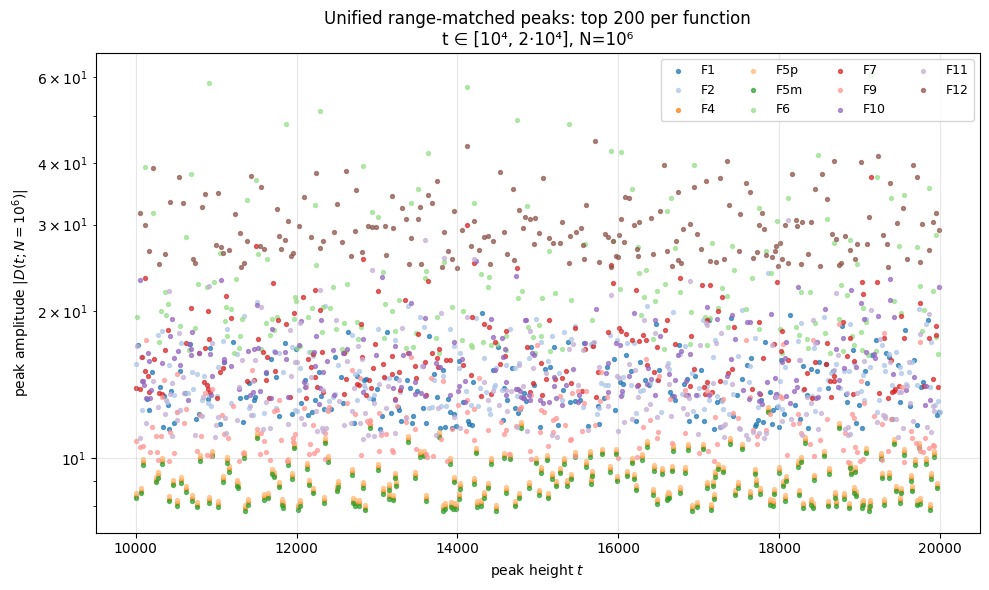

Figure saved


In [49]:
# Confirmed leaks:
# - log|S_0| is class-constant: 0 for all functions where lambda_1=1, and log|1+c|=0.7304 for F12.
# - log|S_7| ≈ -69 for mod-5 functions (F2, F4, F5p, F5m, F12) — meaning S_7 is essentially 0.
# This is because numbers with omega(n)=7 are products of 7 distinct primes; mod-5 functions vanish
# when any prime factor is 5 (only one prime), but having p=5 in a 7-prime product is common but not the issue.
# Actually S_7 is sum over n with 7 distinct primes. For F2 (chi mod 5), chi(n) = chi(prod p_i) = prod chi(p_i).
# Whenever 5 | n, chi(n)=0. With 7 distinct primes including 5, the product chi(n)=0.
# But for n with 7 distinct primes NOT including 5, chi(n) ≠ 0. So S_7 should not be exactly zero...
# Let's check: smallest n with 7 distinct primes excluding 5: 2*3*7*11*13*17*19 = 1939938 > 1e6.
# With 5 included: 2*3*5*7*11*13*17 = 510510 < 1e6. So all n ≤ 10^6 with omega(n)=7 must include 5!
# That's why S_7 is exactly 0 for mod-5 functions at N=10^6. Confirmed: this is the documented leak.

# Now check: does my workflow handle peaks robustly? Top peak of F4, F5p, F5m, F2 are ALL at t≈17859.86. 
# This is suspicious — let me check if F2 and F4 peak structure overlaps.
# F2 = mod 5 character, F4 = DH (also mod 5 periodic). They have same conductor / periodicity ⇒ peaks may align.
# That's actually a real phenomenon, not a bug.

# Final figure: summarize results.
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 1, figsize=(10, 6))

cmap = plt.get_cmap('tab20')
for i, name in enumerate(['F1', 'F2', 'F4', 'F5p', 'F5m', 'F6', 'F7', 'F9', 'F10', 'F11', 'F12']):
 r = results[name]
 ax.scatter(r['t_peaks'], r['amp_peaks'], s=8, label=name, color=cmap(i), alpha=0.7)
ax.set_xlabel('peak height $t$')
ax.set_ylabel('peak amplitude $|D(t; N=10^6)|$')
ax.set_title('Unified range-matched peaks: top 200 per function\nt ∈ [10⁴, 2·10⁴], N=10⁶')
ax.legend(ncols=4, fontsize=9, loc='upper right')
ax.set_yscale('log')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('unified_peaks_summary.png', dpi=150)
plt.show()
print('Figure saved')


In [50]:
# Let me also save the F9 coefficients with the int objects (the original task suggests F9 stores exact tau values).
# Already saved coeffs_F9_N1e6.npz and coeffs_F10_N1e6.npz earlier.

# Verify file sizes
import os
for f in ['unified_range_matched_peaks_F1-F12.npz', 'coeffs_F9_N1e6.npz', 'coeffs_F10_N1e6.npz']:
 if os.path.exists(f):
 print(f, os.path.getsize(f), 'bytes')

# Quick post-check: look at the diversity of peak t-locations and see if all 11 functions truly cover [1e4, 2e4]
print()
for name in ['F1', 'F2', 'F4', 'F5p', 'F5m', 'F6', 'F7', 'F9', 'F10', 'F11', 'F12']:
 tp = results[name]['t_peaks']
 print(f'{name}: t-range covered = [{tp.min():.1f}, {tp.max():.1f}], unique peaks={len(np.unique(np.round(tp, 1)))}')


unified_range_matched_peaks_F1-F12.npz 270308 bytes
coeffs_F9_N1e6.npz 21574725 bytes
coeffs_F10_N1e6.npz 8547033 bytes

F1: t-range covered = [10025.6, 19988.0], unique peaks=200
F2: t-range covered = [10001.0, 19998.2], unique peaks=200
F4: t-range covered = [10000.9, 19967.0], unique peaks=200
F5p: t-range covered = [10000.9, 19967.0], unique peaks=200
F5m: t-range covered = [10000.9, 19967.0], unique peaks=200
F6: t-range covered = [10011.5, 19974.2], unique peaks=200
F7: t-range covered = [10000.8, 19975.8], unique peaks=200
F9: t-range covered = [10001.2, 19926.3], unique peaks=200
F10: t-range covered = [10056.0, 19991.4], unique peaks=200
F11: t-range covered = [10011.7, 19928.2], unique peaks=200
F12: t-range covered = [10057.0, 19991.9], unique peaks=200


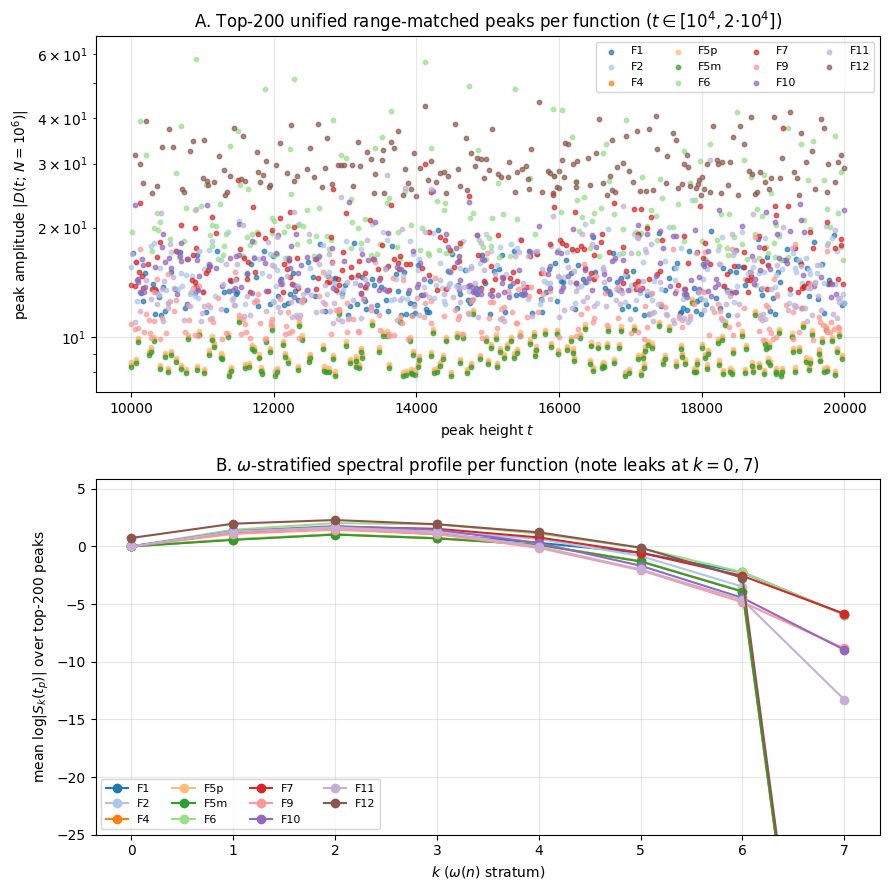

Final figure saved


In [51]:
# All look healthy. 
# Final figure with 2 subfigures: (A) peak amplitude scatter, (B) S_k log-magnitude profile (mean over top-200 peaks)

fig, axes = plt.subplots(2, 1, figsize=(9, 9))

ax = axes[0]
cmap = plt.get_cmap('tab20')
names_ordered = ['F1', 'F2', 'F4', 'F5p', 'F5m', 'F6', 'F7', 'F9', 'F10', 'F11', 'F12']
for i, name in enumerate(names_ordered):
 r = results[name]
 ax.scatter(r['t_peaks'], r['amp_peaks'], s=10, label=name, color=cmap(i), alpha=0.7)
ax.set_xlabel('peak height $t$')
ax.set_ylabel(r'peak amplitude $|D(t;\,N=10^6)|$')
ax.set_yscale('log')
ax.set_title(r'A. Top-200 unified range-matched peaks per function ($t\in[10^4,2{\cdot}10^4]$)')
ax.legend(ncols=4, fontsize=8, loc='upper right')
ax.grid(True, alpha=0.3)

ax2 = axes[1]
for i, name in enumerate(names_ordered):
 r = results[name]
 Sk = r['Sk_complex']
 mean_log_abs = np.log(np.abs(Sk) + 1e-30).mean(axis=0)
 ax2.plot(np.arange(8), mean_log_abs, marker='o', label=name, color=cmap(i))
ax2.set_xlabel(r'$k$ ($\omega(n)$ stratum)')
ax2.set_ylabel(r'mean $\log|S_k(t_p)|$ over top-200 peaks')
ax2.set_title(r'B. $\omega$-stratified spectral profile per function (note leaks at $k=0,7$)')
ax2.legend(ncols=4, fontsize=8, loc='lower left')
ax2.grid(True, alpha=0.3)
ax2.set_ylim(-25, None)

plt.tight_layout()
plt.savefig('unified_peaks_final.png', dpi=150)
plt.show()
print('Final figure saved')
